### Objective of the project-
To develop a predictive model that forecasts Apple stock prices for the next 30 days using historical stock data from 2012 to 2019. The model will help investors, traders, and financial analysts make informed decisions based on stock trends and potential market movements.

### Week 1-Exploratory Data Analysis

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings("ignore")

######  Pandas is used for data manipulation and datetime operations, NumPy for numerical calculations, Matplotlib and Seaborn for visualizations, and warnings for displaying relevant runtime notices. Plot settings standardize the appearance of charts.

### Load the CSV dataset

In [2]:
data=pd.read_csv("/content/P721 DATASET.csv")


##### The CSV file is loaded into a Pandas DataFrame. The original data is retained in `data`; subsequent exploratory columns will be added only when needed.

### View the first five rows

In [3]:
data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


### View the last five rows

In [4]:
data.tail()

,Date,Open,High,Low,Close,Adj Close,Volume
2006,2019-12-23,280.529999,284.250000,280.369995,284.000000,282.054138,24643000
2007,2019-12-24,284.690002,284.890015,282.920013,284.269989,282.322266,12119700
2008,2019-12-26,284.820007,289.980011,284.700012,289.910004,287.923645,23280300
2009,2019-12-27,291.119995,293.970001,288.119995,289.799988,287.814392,36566500
2010,2019-12-30,289.459991,292.690002,285.220001,291.519989,289.522614,36028600


### Check dataset size

In [5]:
data.shape

(2011, 7)

##### The DataFrame shape reports the number of observations and variables. The uploaded dataset is expected to contain 2,011 rows and seven columns.

##### This tells you how many recorded trading days and fields are in the file. If your output differs from the expected size, check that you loaded the correct CSV.

### Inspect columns names

In [6]:
print(data.columns.tolist())

['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


### Inspect dataset structure and data types

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2011 entries, 0 to 2010
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2011 non-null   object 
 1   Open       2011 non-null   float64
 2   High       2011 non-null   float64
 3   Low        2011 non-null   float64
 4   Close      2011 non-null   float64
 5   Adj Close  2011 non-null   float64
 6   Volume     2011 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 110.1+ KB


##### the structure summary shows each column's data type and non null count.Data values commonly load as strings and should be converted to datetime before time-based .
##### This tells you whether a column is treated as text or as a number, and whether it contains missing values. Python needs proper dates for time-series work.

### Generate the statistical summary

In [8]:
data.describe().round(2)

,Open,High,Low,Close,Adj Close,Volume
count,2011.00,2011.00,2011.00,2011.00,2011.00,2.011000e+03
mean,126.71,127.83,125.58,126.74,119.51,5.949670e+07
std,50.48,50.93,50.12,50.58,52.44,4.683856e+07
min,55.42,57.09,55.01,55.79,48.92,1.136200e+07
25%,85.88,86.72,85.06,86.20,75.06,2.758565e+07
50%,113.05,114.19,111.87,113.05,105.22,4.346900e+07
75%,165.19,167.41,163.42,165.25,160.05,7.471030e+07
max,291.12,293.97,288.12,291.52,289.52,3.765300e+08


#### Descriptive statistics summarize the numeric variables using count, mean, standard deviation, minimum, quartiles, and maximum. These summaries describe the whole period but do not preserve the order of time.

### Convert Date to datetime


In [9]:
data["Date"]=pd.to_datetime(data["Date"],errors="coerce")
print("Invalid dates:",data["Date"].isna().sum())
data[["Date"]].head()

Invalid dates: 0


,Date
0,2012-01-03
1,2012-01-04
2,2012-01-05
3,2012-01-06
4,2012-01-09



##### The `Date` column is converted to Pandas datetime. Invalid date strings are converted to `NaT` so they can be identified and investigated.

##### We convert date text into real dates so Python can sort by time, group by year or month, and draw the timeline correctly.

### Sort observations chronologically

In [10]:
data=data.sort_values("Date").reset_index(drop=True)
print("Chronological order:",data["Date"].is_monotonic_increasing)
data.head()

Chronological order: True


,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


##### Observations are sorted from earliest to latest and the row index is reset. Chronological order is essential for calculating returns, rolling statistics, and future forecasts correctly.

### Check the date range

In [11]:
print("Satrt date:",data["Date"].min())
print("End date:",data["Date"].max())
print("Number of observation:",len(data))

Satrt date: 2012-01-03 00:00:00
End date: 2019-12-30 00:00:00
Number of observation: 2011


##### The earliest and latest valid dates establish the historical coverage. The provided dataset is described as covering 2012–2019; this code confirms the dates actually present in the loaded file.
##### This confirms the period covered by your file. It also helps us later decide where the training period ends and the test period begins.

### Data quality and time index

#####
Check missing values

In [12]:
data.isnull().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


######  The number of missing values is calculated for every column. Missing values should be investigated before modeling; they should not be filled automatically without understanding the cause.

### Calculate missing-value percentages

In [13]:
missing_percentage=(data.isnull().mean()*100).round(2)
print(missing_percentage)

Date         0.0
Open         0.0
High         0.0
Low          0.0
Close        0.0
Adj Close    0.0
Volume       0.0
dtype: float64


##### The fraction of missing values in each column is converted to a percentage. This makes missingness easier to compare across variables.


### Check duplicate rows and duplicate dates

In [14]:
print("Duplicate rows:",data.duplicated().sum())
print("Duplicate dates:",data["Date"].duplicated().sum())

Duplicate rows: 0
Duplicate dates: 0


##### Complete duplicate rows and repeated timestamps are checked separately. Multiple records for one date should be investigated before removal, since repeated dates can have different meanings in other datasets.
##### A duplicated record can give the same observation extra weight. Two rows with the same date also need checking, but do not delete them without inspecting them first.

### Check chronological order and invalid dates

In [15]:
print("Dates in ascending order:",data["Date"].is_monotonic_increasing)
print("Invalid dates:",data["Date"].isnull().sum())

Dates in ascending order: True
Invalid dates: 0


##### These checks confirm that the date index is sorted and that no date failed parsing. Any invalid dates should be resolved before setting the index.
##### This is a quick safety check: dates should be sorted, and each date should be valid.

### Validate OHLC(open,high,low,close) price relationships

In [16]:
invalid_prices=data[
    (data["High"]<data["Low"])|
    (data["High"]<data["Low"])|
    (data["High"]<data["Low"])|
    (data["High"]<data["Low"])|
    (data["High"]<data["Low"])
 ]
print("Rows with inconsistent OHLC prices:",len(invalid_prices))
invalid_prices.head()

Rows with inconsistent OHLC prices: 0


,Date,Open,High,Low,Close,Adj Close,Volume



##### The high and low values are checked against the open and close values. Rows violating the basic OHLC relationships are flagged for inspection, not automatically deleted.

### Inscept gaps between recorded dates

In [17]:
date_gaps=data["Date"].diff().dt.days
print(date_gaps.value_counts().sort_index().head(15))

Date
1.0    1570
2.0      23
3.0     367
4.0      49
5.0       1
Name: count, dtype: int64


#####  Calendar-day differences between consecutive observations are summarized. Weekends and exchange holidays naturally create gaps; a gap alone does not prove that a trading observation is missing.

### Count observations by year

In [18]:
observations_per_year=data.groupby(data["Date"].dt.year).size()
print(observations_per_year)

Date
2012    250
2013    252
2014    252
2015    252
2016    252
2017    251
2018    251
2019    251
dtype: int64


##### The number of recorded observations is counted by calendar year. Unusual counts may warrant checking against the market calendar and data coverage.
##### This shows how many records appear in each year and helps identify years worth checking.

### Set Date as the time-series index

In [19]:
ts_data=data.set_index("Date").sort_index()
print("Index type:",type(ts_data.index))
print("Index is sorted:",ts_data.index.is_monotonic_increasing)
ts_data.head()

Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Index is sorted: True


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


###### A DatetimeIndex is created to support time-based slicing, resampling, rolling analysis and plotting. The original data DataFrame is retained, and ts_data is a time-indexed version.
##### This makes Date the index of the table. It is convenient for time-series operations, and we keep the original table too.

### Summarize data quality checks

In [20]:
quality_summary = pd.Series({
    "Observations": len(data),
    "Columns": data.shape[1],
    "Missing dates": data["Date"].isna().sum(),
    "Duplicate rows": data.duplicated().sum(),
    "Duplicate dates": data["Date"].duplicated().sum(),
    "Inconsistent OHLC rows": len(invalid_prices),
    "Start date": str(data["Date"].min().date()),
    "End date": str(data["Date"].max().date())
})
quality_summary

,0
Observations,2011
Columns,7
Missing dates,0
Duplicate rows,0
Duplicate dates,0
Inconsistent OHLC rows,0
Start date,2012-01-03
End date,2019-12-30


##### A compact summary combines key data-quality checks and date coverage. The OHLC count refers to the rows flagged in Step 16.
This collects the main quality results in one place for your final report.

### Price statistics and distributions

### Summarize original price and volume columns

In [21]:
price_volume_cols=["Open","High","Low","Close","Adj Close","Volume"]
data[price_volume_cols].describe().round(2)

,Open,High,Low,Close,Adj Close,Volume
count,2011.00,2011.00,2011.00,2011.00,2011.00,2.011000e+03
mean,126.71,127.83,125.58,126.74,119.51,5.949670e+07
std,50.48,50.93,50.12,50.58,52.44,4.683856e+07
min,55.42,57.09,55.01,55.79,48.92,1.136200e+07
25%,85.88,86.72,85.06,86.20,75.06,2.758565e+07
50%,113.05,114.19,111.87,113.05,105.22,4.346900e+07
75%,165.19,167.41,163.42,165.25,160.05,7.471030e+07
max,291.12,293.97,288.12,291.52,289.52,3.765300e+08


##### Descriptive statistics are calculated for the original numeric market variables. Price columns and volume use different units and should not be compared by raw magnitude.
This summarizes the price and volume fields. Volume counts shares; prices are monetary values.

### Compare closing-price mean, median, minimum and maximum

In [22]:
print("Mean close:", data["Close"].mean())
print("Median close:", data["Close"].median())
print("Minimum close:", data["Close"].min())
print("Maximum close:", data["Close"].max())

Mean close: 126.74123461064147
Median close: 113.050003
Minimum close: 55.790001
Maximum close: 291.519989


##### Central tendency and range statistics are calculated for Close. For a trending series, these full-period statistics can be influenced by changes in price level over time.
This shows the average, middle, lowest and highest closing prices. These numbers do not show when those prices occurred.

##### Calculate daily trading range

In [23]:
data["Daily_Range"] = data["High"] - data["Low"]
data[["Date", "High", "Low", "Daily_Range"]].head(10)

,Date,High,Low,Daily_Range
0,2012-01-03,58.928570,58.428570,0.500000
1,2012-01-04,59.240002,58.468571,0.771431
2,2012-01-05,59.792858,58.952858,0.840000
3,2012-01-06,60.392857,59.888573,0.504284
4,2012-01-09,61.107143,60.192856,0.914287
5,2012-01-10,60.857143,60.214287,0.642856
6,2012-01-11,60.407143,59.901428,0.505715
7,2012-01-12,60.414288,59.821430,0.592858
8,2012-01-13,60.064285,59.808571,0.255714
9,2012-01-17,60.855713,60.422855,0.432858


##### The intraday range is calculated as High minus Low. This is an absolute price-range feature and differs from the percentage return between sessions.
This measures the difference between the day's high and low. It is not the same as the change from yesterday's close.

### Plot the closing-price distribution

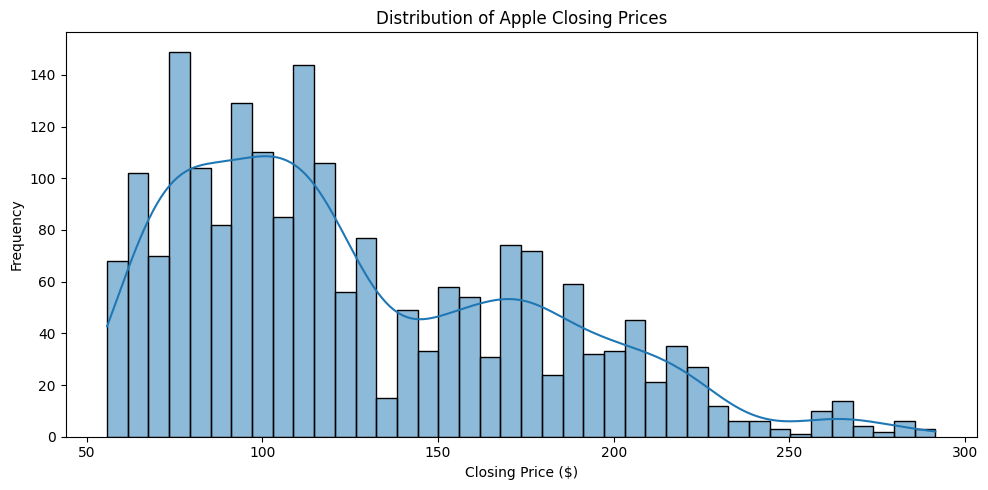

In [24]:
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x="Close", bins=40, kde=True)
plt.title("Distribution of Apple Closing Prices")
plt.xlabel("Closing Price ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

###### A histogram displays the frequency distribution of closing-price levels. Because price levels can trend over time, the histogram combines observations from different historical price regimes and should be interpreted alongside the time plot.
This shows which price levels appeared most often. It mixes prices from different years, so it cannot show the trend by itself.

### Compare closing-price distributions by year

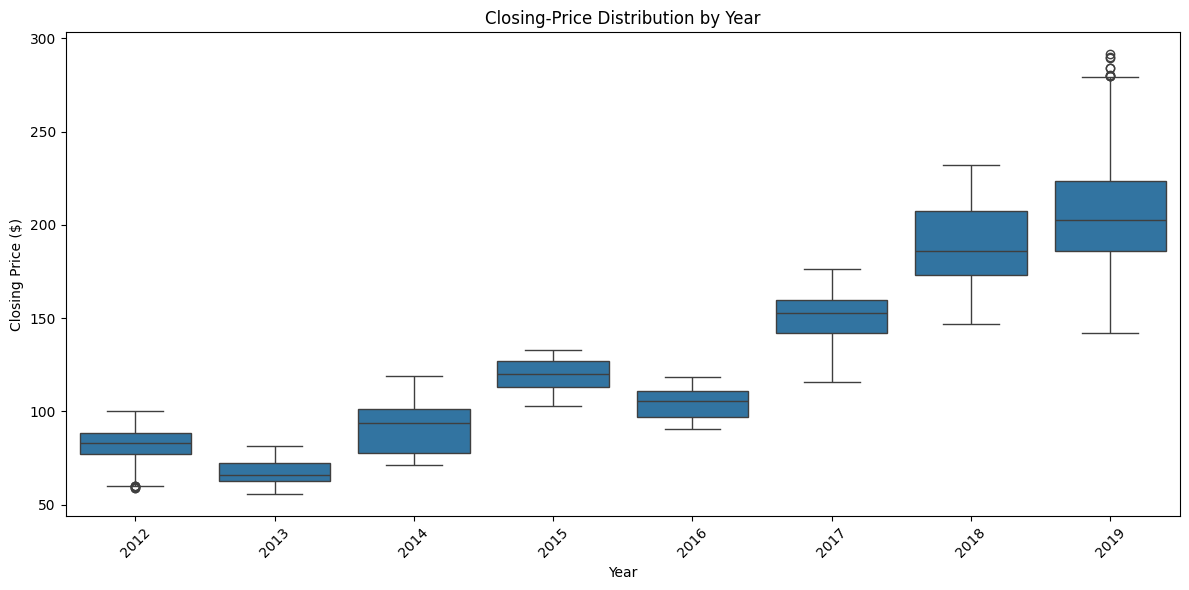

In [25]:
plot_data = data.assign(Year=data["Date"].dt.year)

plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_data, x="Year", y="Close")
plt.title("Closing-Price Distribution by Year")
plt.xlabel("Year")
plt.ylabel("Closing Price ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Annual boxplots compare median, interquartile range and potential extreme values of closing prices. They do not preserve within-year chronology.
This compares price levels year by year, but it does not show the sequence of rises and falls within each year.

### Trend and time-based visualizations

####  Plot closing price over time

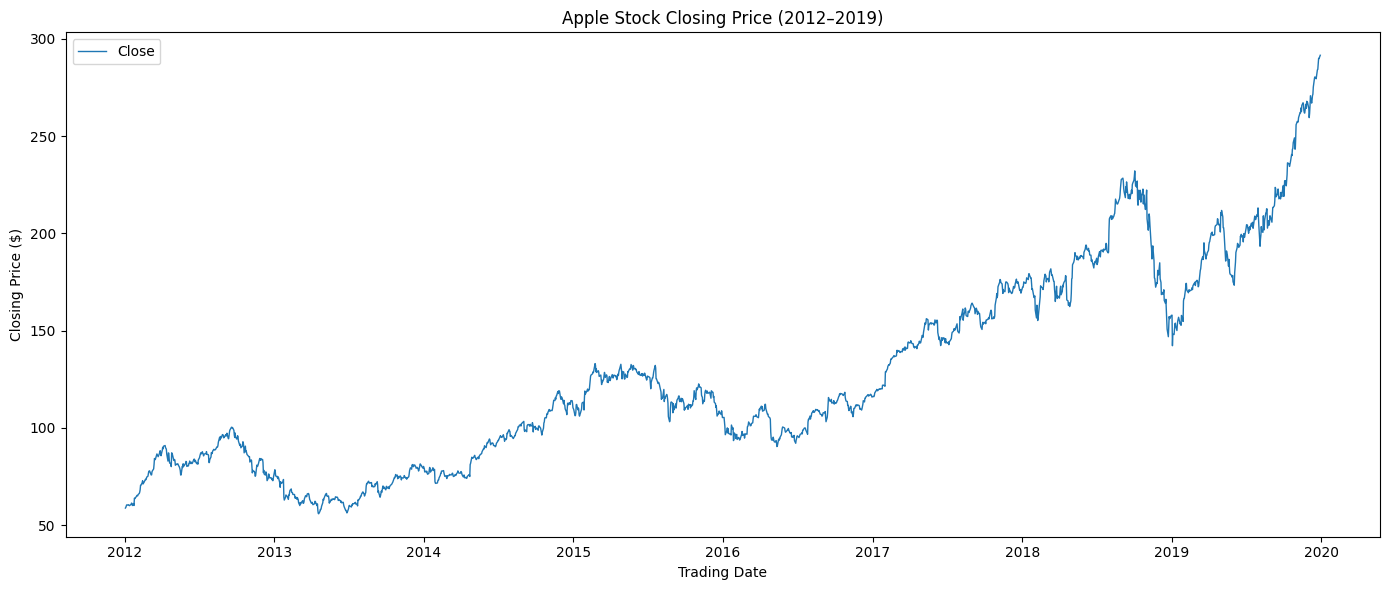

In [26]:
plt.figure(figsize=(14, 6))
plt.plot(data["Date"], data["Close"], label="Close", linewidth=1)
plt.title("Apple Stock Closing Price (2012–2019)")
plt.xlabel("Trading Date")
plt.ylabel("Closing Price ($)")
plt.legend()
plt.tight_layout()
plt.show()

###### A line chart plots closing price against trading date while preserving chronology. It is the primary visualization for examining long-term trend and periods of unusual movement.
This is one of the most important charts. Time goes on the X-axis and closing price on the Y-axis. Describe what you actually see.

### Plot Open, High, Low and Close over time

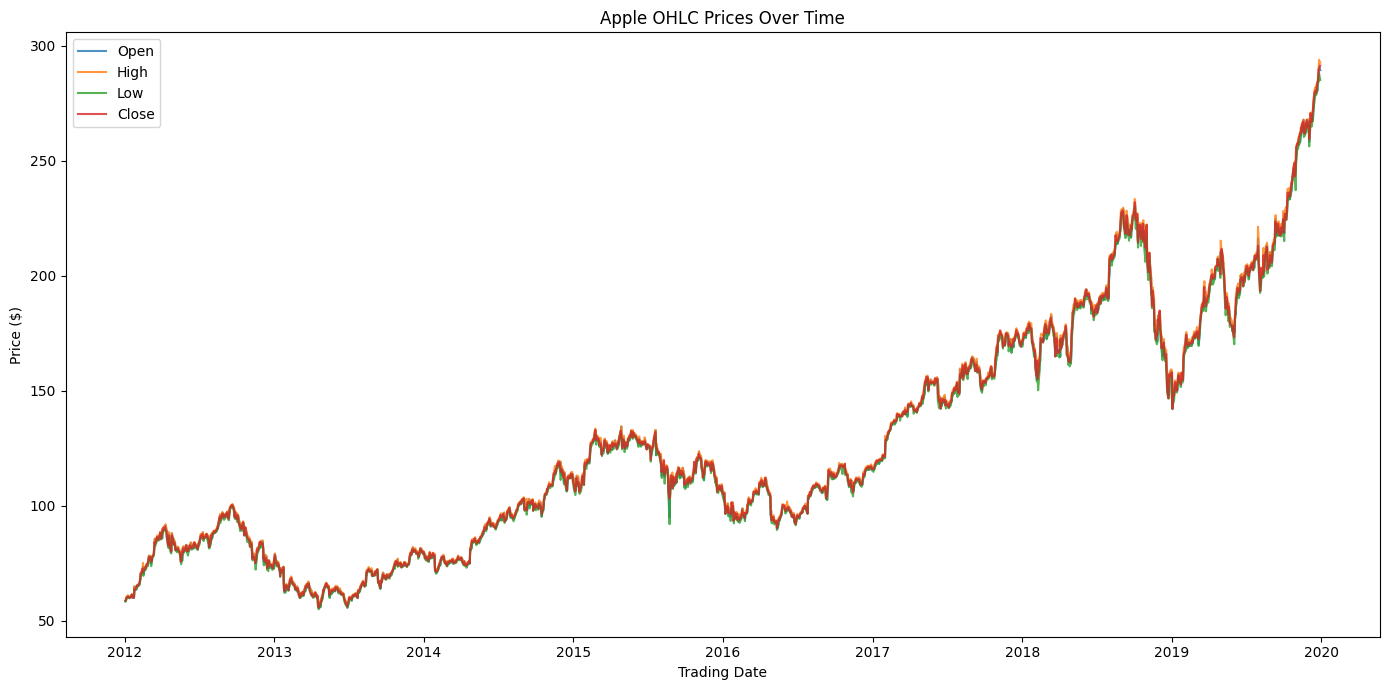

In [27]:
plt.figure(figsize=(14, 7))
for col in ["Open", "High", "Low", "Close"]:
    plt.plot(data["Date"], data[col], label=col, alpha=0.8)
plt.title("Apple OHLC Prices Over Time")
plt.xlabel("Trading Date")
plt.ylabel("Price ($)")
plt.legend()
plt.tight_layout()
plt.show()

###### The four OHLC price series are plotted on the same timeline. Because they describe the same trading session, their values are closely related and their lines may overlap.
This compares opening, highest, lowest and closing prices over time. The lines will be close together because they describe the same stock session.

### Compare Close and Adjusted Close

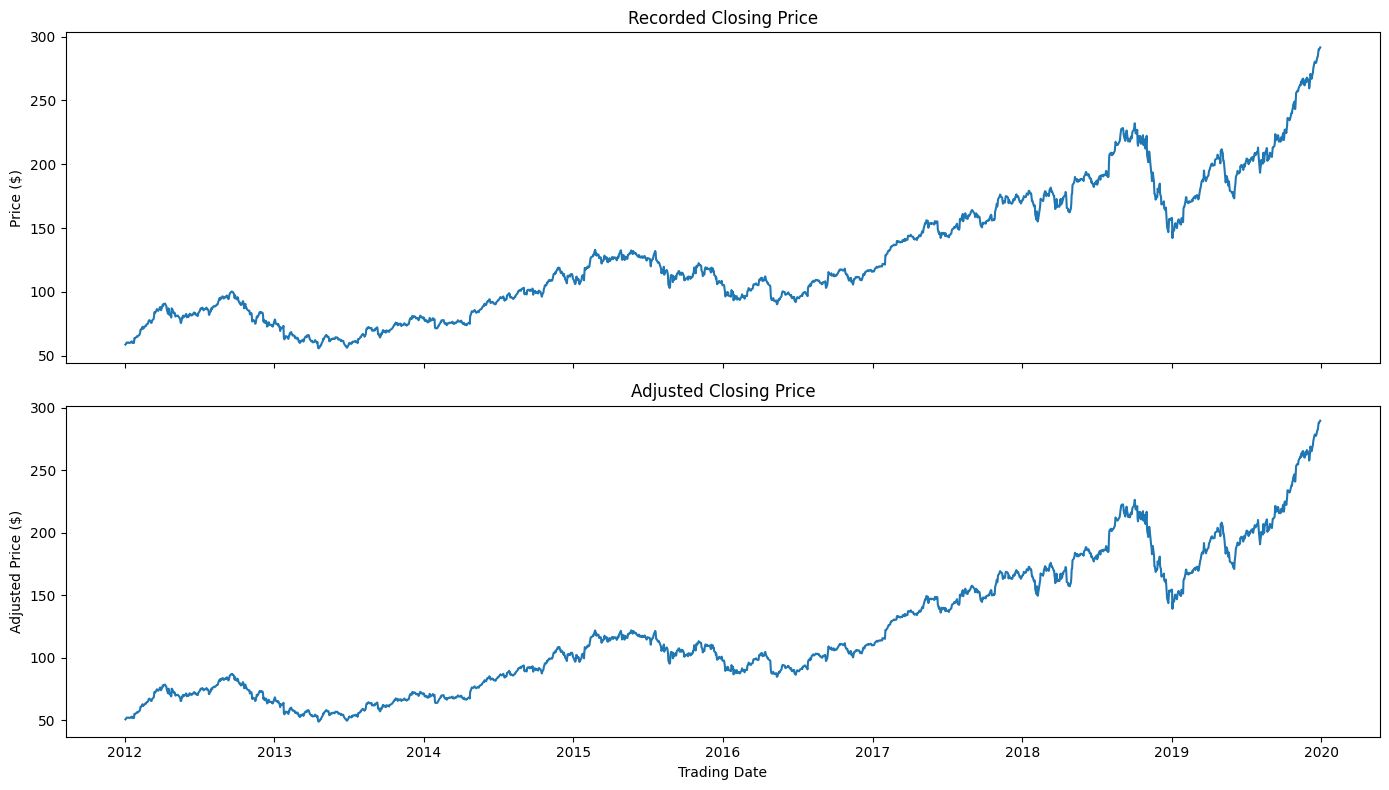

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(data["Date"], data["Close"])
axes[0].set_title("Recorded Closing Price")
axes[0].set_ylabel("Price ($)")
axes[1].plot(data["Date"], data["Adj Close"])
axes[1].set_title("Adjusted Closing Price")
axes[1].set_xlabel("Trading Date")
axes[1].set_ylabel("Adjusted Price ($)")
plt.tight_layout()
plt.show()

##### The two price series are plotted separately. Adjusted close may account for dividends and splits depending on source methodology; choose the forecasting target consistently after confirming the dataset's provenance.
This shows how Close and Adj Close differ. We must choose which one to forecast and use that choice consistently throughout the project.

### Calculate and plot yearly average closing prices

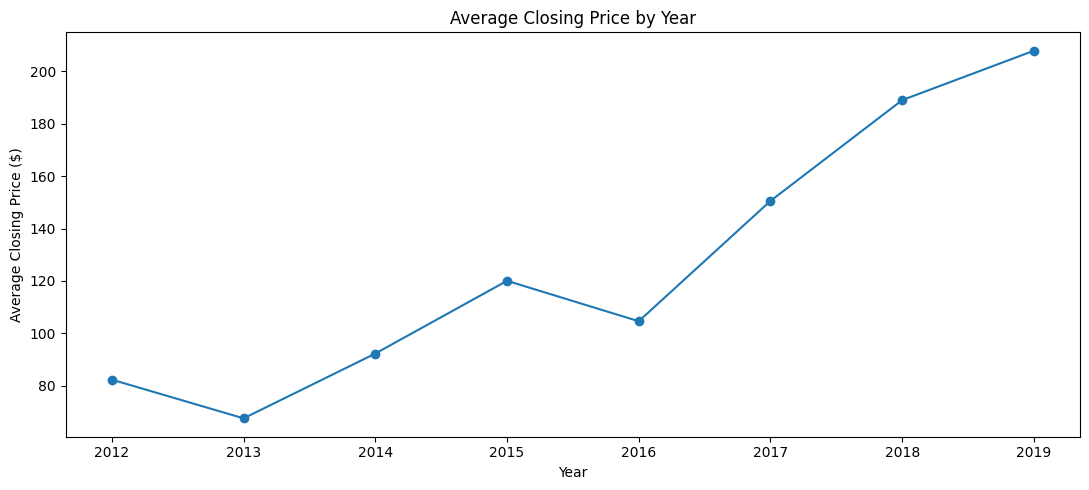

In [29]:
yearly_average_close = data.groupby(data["Date"].dt.year)["Close"].mean()
plt.figure(figsize=(11, 5))
plt.plot(yearly_average_close.index, yearly_average_close.values, marker="o")
plt.title("Average Closing Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Closing Price ($)")
plt.xticks(yearly_average_close.index)
plt.tight_layout()
plt.show()

###### Daily closes are aggregated into annual arithmetic means. This summarizes annual price levels but removes the daily sequence, so it does not replace the daily time-series plot.
This reduces each year to one average and gives a quick comparison, but hides daily changes.

### Returns, volume and potential outliers

### Calculate daily percentage returns

In [30]:
data["Daily_Return"] = data["Close"].pct_change() * 100
data[["Date", "Close", "Daily_Return"]].head(10)

,Date,Close,Daily_Return
0,2012-01-03,58.747143,NaN
1,2012-01-04,59.062859,0.537415
2,2012-01-05,59.718571,1.110193
3,2012-01-06,60.342857,1.045380
4,2012-01-09,60.247143,-0.158617
5,2012-01-10,60.462856,0.358047
6,2012-01-11,60.364285,-0.163027
7,2012-01-12,60.198570,-0.274525
8,2012-01-13,59.972858,-0.374946
9,2012-01-17,60.671429,1.164812


##### Daily percentage return is calculated as the percentage change between consecutive closing-price observations. The first return is missing because there is no previous observation.
This tells us how much the closing price changed compared with the previous recorded session. Positive means up; negative means down.

### Plot daily returns over time

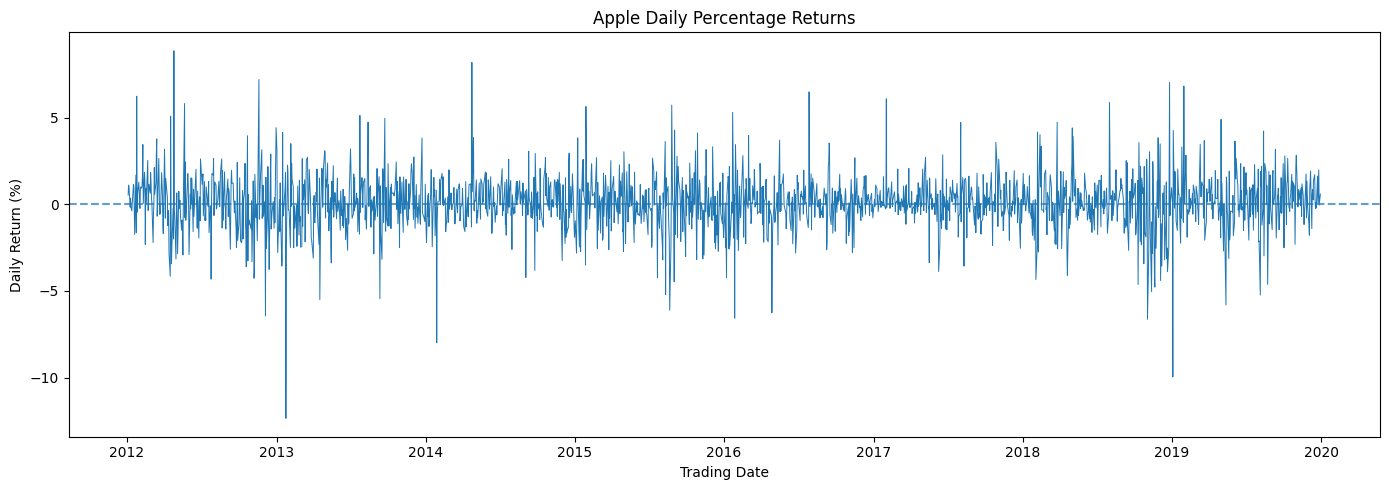

In [31]:
plt.figure(figsize=(14, 5))
plt.plot(data["Date"], data["Daily_Return"], linewidth=0.7)
plt.axhline(0, linestyle="--", alpha=0.7)
plt.title("Apple Daily Percentage Returns")
plt.xlabel("Trading Date")
plt.ylabel("Daily Return (%)")
plt.tight_layout()
plt.show()

###### The return series is plotted with a zero reference line to distinguish positive and negative changes and identify large movements.
This chart focuses on daily changes rather than the stock's absolute price level.

### Plot daily-return distribution

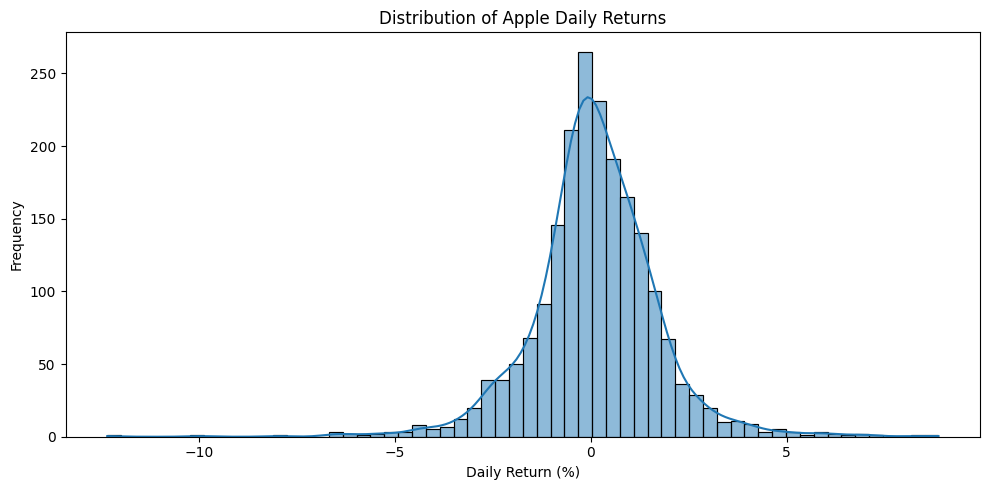

In [32]:
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x="Daily_Return", bins=60, kde=True)
plt.title("Distribution of Apple Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

##### A histogram summarizes daily percentage returns. It helps inspect concentration around zero and extreme values but does not prove a particular theoretical distribution.
This shows which daily percentage changes happened most often and whether there were unusually large movements.

### Flag potential return outliers with the IQR rule

In [33]:
returns = data["Daily_Return"].dropna()
q1 = returns.quantile(0.25)
q3 = returns.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (data["Daily_Return"] < lower_bound) |
    (data["Daily_Return"] > upper_bound)
)
return_outliers = data.loc[
    outlier_mask, ["Date", "Close", "Daily_Return", "Volume"]
]

print("Potential return outliers:", len(return_outliers))
return_outliers.head(10)

Potential return outliers: 102


,Date,Close,Daily_Return,Volume
15,2012-01-25,63.808571,6.243905,239578500
26,2012-02-09,70.452858,3.459342,221053700
49,2012-03-14,84.225716,3.781026,354711000
71,2012-04-16,82.875717,-4.147178,262696700
72,2012-04-17,87.099998,5.097128,256382000
74,2012-04-19,83.919998,-3.435583,208679800
78,2012-04-25,87.142860,8.874137,226444400
81,2012-04-30,83.425713,-3.154234,126536200
96,2012-05-21,80.182854,5.826009,157776500
141,2012-07-25,82.138573,-4.318373,219328200


##### The interquartile-range rule flags returns below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. This is an exploratory flagging method, not proof of an error; genuine market events can produce extreme returns.
This finds unusually large daily moves compared with the middle half of returns. Do not delete them automatically; investigate the dates and data source.

### Plot trading volume over time

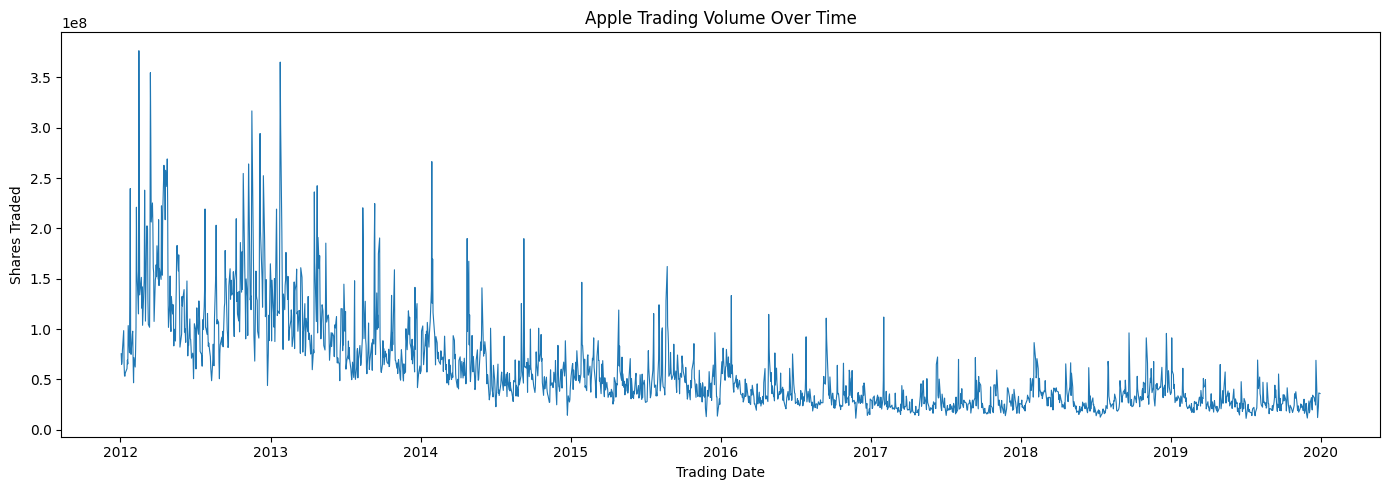

In [34]:
plt.figure(figsize=(14, 5))
plt.plot(data["Date"], data["Volume"], linewidth=0.8)
plt.title("Apple Trading Volume Over Time")
plt.xlabel("Trading Date")
plt.ylabel("Shares Traded")
plt.tight_layout()
plt.show()

##### Trading volume is plotted against date to identify changes in activity and high-volume sessions. The chart does not by itself establish why a spike occurred.
This shows how many shares were traded in each session and when trading was unusually active.

### Inspect the distribution of trading volume

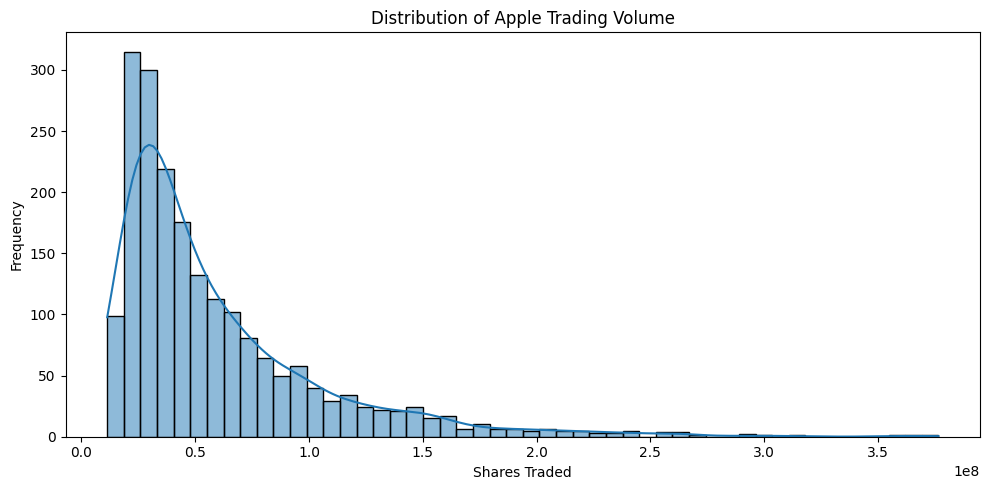

In [35]:
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x="Volume", bins=50, kde=True)
plt.title("Distribution of Apple Trading Volume")
plt.xlabel("Shares Traded")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

##### The histogram summarizes volume frequency. A small number of very high-volume sessions can create a right-skewed distribution.
This shows whether most days have similar trading volume or whether a few days have much higher volume.

### Explore volume versus absolute daily return

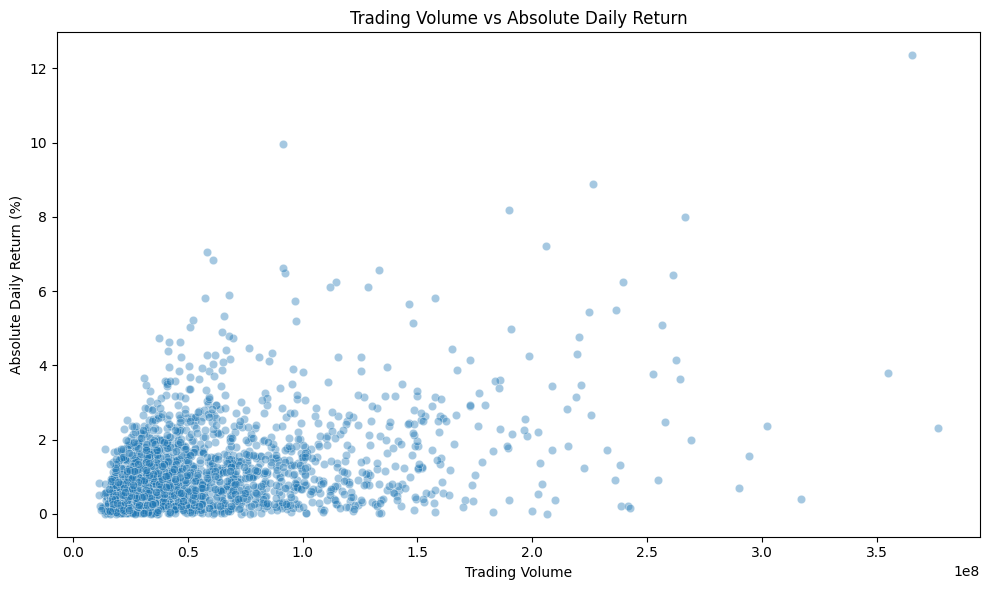

In [36]:
data["Absolute_Daily_Return"] = data["Daily_Return"].abs()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x="Volume", y="Absolute_Daily_Return", alpha=0.4)
plt.title("Trading Volume vs Absolute Daily Return")
plt.xlabel("Trading Volume")
plt.ylabel("Absolute Daily Return (%)")
plt.tight_layout()
plt.show()

##### A scatter plot explores whether trading volume is associated with the magnitude of daily returns. This is descriptive only and does not establish causation.
This checks whether higher-volume sessions also tend to have larger price moves. A chart alone cannot tell us whether volume caused the move.

### Moving averages, volatility, monthly patterns and stationarity

 ### Calculate moving averages


In [37]:
data["MA_20"] = data["Close"].rolling(window=20).mean()
data["MA_50"] = data["Close"].rolling(window=50).mean()
data["MA_200"] = data["Close"].rolling(window=200).mean()
data[["Date", "Close", "MA_20", "MA_50", "MA_200"]].tail()

,Date,Close,MA_20,MA_50,MA_200
2006,2019-12-23,284.000000,271.181998,259.6744,216.52925
2007,2019-12-24,284.269989,272.076997,260.6424,217.04605
2008,2019-12-26,289.910004,273.357997,261.7342,217.58705
2009,2019-12-27,289.799988,274.455997,262.8428,218.11740
2010,2019-12-30,291.519989,275.669496,263.9676,218.64440


##### Trailing moving averages are calculated over 20, 50 and 200 recorded trading observations. The first values are missing until a full window is available. These features use the current and previous observations only.
These averages smooth price movements over short, medium and longer windows. Missing values at the start are expected.

### Plot moving averages

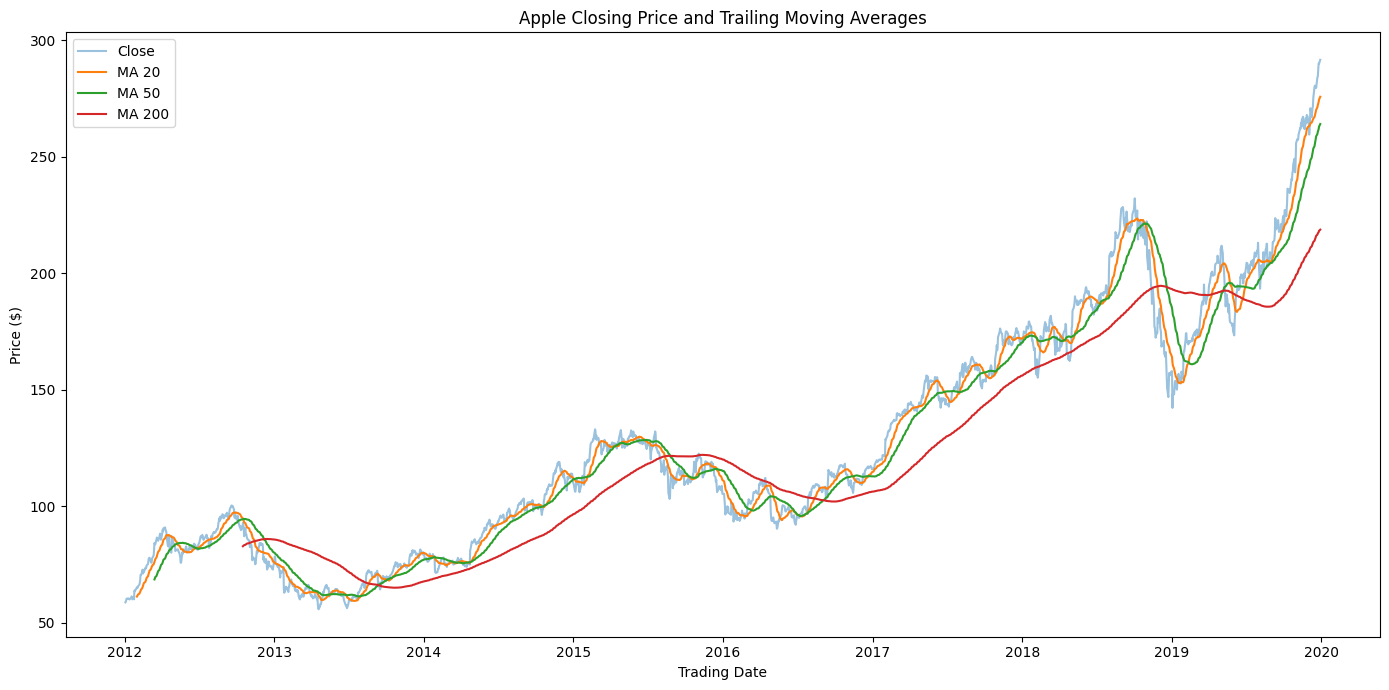

In [38]:
plt.figure(figsize=(14, 7))
plt.plot(data["Date"], data["Close"], label="Close", alpha=0.45)
plt.plot(data["Date"], data["MA_20"], label="MA 20")
plt.plot(data["Date"], data["MA_50"], label="MA 50")
plt.plot(data["Date"], data["MA_200"], label="MA 200")
plt.title("Apple Closing Price and Trailing Moving Averages")
plt.xlabel("Trading Date")
plt.ylabel("Price ($)")
plt.legend()
plt.tight_layout()
plt.show()

##### The closing-price series is compared with trailing moving averages to visualize trends at different smoothing windows. These are descriptive indicators, not guaranteed trading signals.
The short average reacts faster; the long average is smoother. The chart helps you describe historical trends.

### Calculate rolling volatility

In [39]:
data["Volatility_20"] = data["Daily_Return"].rolling(window=20).std()
data[["Date", "Daily_Return", "Volatility_20"]].tail(10)

,Date,Daily_Return,Volatility_20
2001,2019-12-16,1.711790,1.149193
2002,2019-12-17,0.196534,1.147882
2003,2019-12-18,-0.238941,1.146340
2004,2019-12-19,0.100093,1.097922
2005,2019-12-20,-0.207123,1.090381
2006,2019-12-23,1.631834,1.123160
2007,2019-12-24,0.095067,1.079452
2008,2019-12-26,1.984035,1.106245
2009,2019-12-27,-0.037948,1.091848
2010,2019-12-30,0.593513,1.082624


##### The rolling standard deviation of daily percentage returns is calculated over 20 observations. It measures recent return dispersion and is not annualized.
This measures how much daily returns varied over the recent 20 sessions. Higher values indicate more variable returns.

### Plot rolling volatility

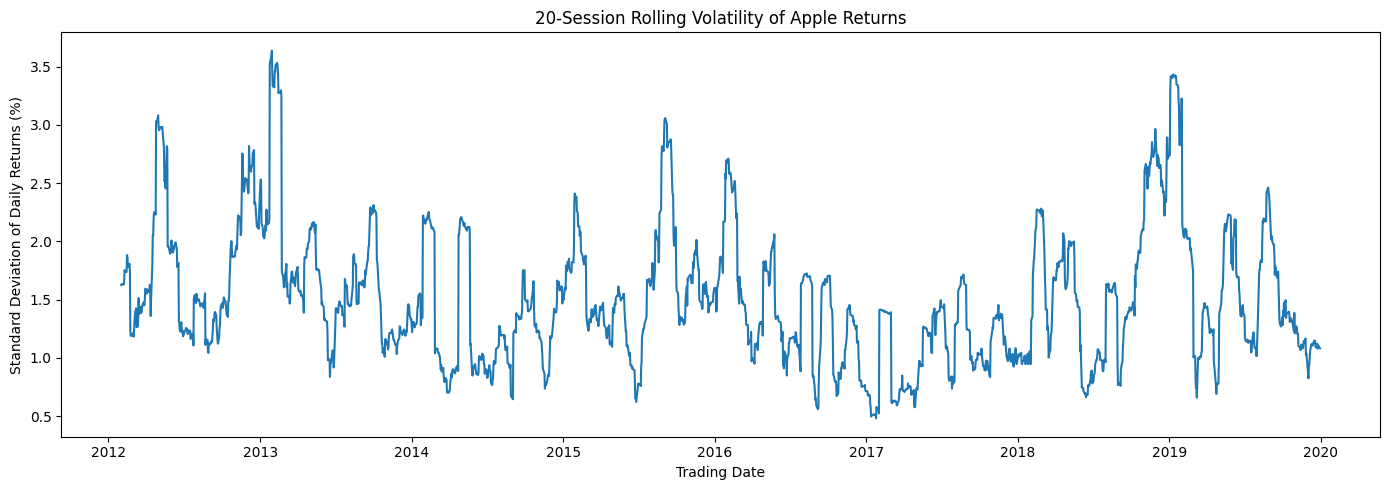

In [40]:
plt.figure(figsize=(14, 5))
plt.plot(data["Date"], data["Volatility_20"])
plt.title("20-Session Rolling Volatility of Apple Returns")
plt.xlabel("Trading Date")
plt.ylabel("Standard Deviation of Daily Returns (%)")
plt.tight_layout()
plt.show()

##### The rolling-volatility series is plotted over time to identify periods of higher or lower return variability. Peaks should be investigated rather than automatically treated as errors.
This shows when the stock's daily percentage changes were more or less variable.

### Create monthly closing prices

In [41]:
monthly_close = (
    data.set_index("Date")["Close"]
    .resample("ME")
    .last()
    .dropna()
)
monthly_close.head()

,Close
Date,
2012-01-31,65.211426
2012-02-29,77.491432
2012-03-31,85.650002
2012-04-30,83.425713
2012-05-31,82.532860


##### The last available recorded closing price in each calendar month is selected to create a monthly series. The original daily series is preserved; monthly aggregation is used only for exploration.
This takes the final available close in each month. It does not create prices for non-trading days

### Calculate monthly returns

In [42]:
monthly_returns = monthly_close.pct_change() * 100
monthly_returns = monthly_returns.dropna()
monthly_returns.head()

,Close
Date,
2012-02-29,18.831065
2012-03-31,10.528351
2012-04-30,-2.596951
2012-05-31,-1.070237
2012-06-30,1.085282


##### Monthly percentage returns are calculated from consecutive month-end closing prices. The first monthly return is missing because there is no previous month-end value in the series.
his measures the percentage change from one month's final closing price to the next month's final closing price

### Explore average returns by calendar month

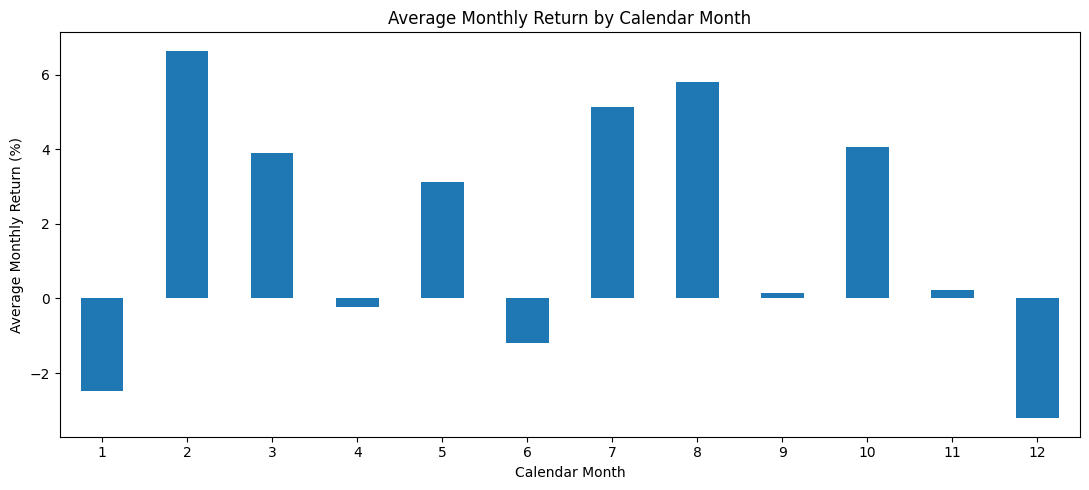

In [43]:
monthly_return_table = pd.DataFrame({
    "Return": monthly_returns,
    "Month": monthly_returns.index.month
})
average_monthly_returns = monthly_return_table.groupby("Month")["Return"].mean()

plt.figure(figsize=(11, 5))
average_monthly_returns.plot(kind="bar")
plt.title("Average Monthly Return by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Average Monthly Return (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Monthly returns are grouped by the calendar month in which each return ends and averaged to explore possible calendar patterns. With roughly eight observations per month category, this is exploratory and cannot establish reliable seasonality by itself.
This compares average returns by month name. There are only a few years of data for each month category, so do not overstate the pattern.

### Run the Augmented Dickey-Fuller stationarity test

In [44]:
for name, series in [
    ("Closing Price", data["Close"].dropna()),
    ("Daily Returns", data["Daily_Return"].dropna())
]:
    result = adfuller(series, autolag="AIC")
    print(f"\n{name}")
    print("ADF statistic:", result[0])
    print("P-value:", result[1])
    print("Critical values:", result[4])


Closing Price
ADF statistic: 1.2193701254378007
P-value: 0.9961170178032009
Critical values: {'1%': np.float64(-3.433622218212895), '5%': np.float64(-2.8629854902259004), '10%': np.float64(-2.5675395171404802)}

Daily Returns
ADF statistic: -15.852960945107087
P-value: 9.402165938786095e-29
Critical values: {'1%': np.float64(-3.433620581635353), '5%': np.float64(-2.862984767669893), '10%': np.float64(-2.5675391324160355)}


##### The ADF test evaluates a unit-root null hypothesis. At a conventional 5% threshold, a p-value below 0.05 is evidence against the unit-root null under the test assumptions. Results must be considered alongside plots and possible structural breaks.
This is one check of whether the statistical behavior is stable over time. A p-value below 0.05 is evidence against a unit root, not proof that every stationarity assumption is satisfied.

### Correlations, external-event limitations and report

### Create a correlation matrix for original numeric variables

In [45]:
original_numeric_cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
correlation_matrix = data[original_numeric_cols].corr()
correlation_matrix.round(2)

,Open,High,Low,Close,Adj Close,Volume
Open,1.00,1.00,1.00,1.00,1.00,-0.56
High,1.00,1.00,1.00,1.00,1.00,-0.55
Low,1.00,1.00,1.00,1.00,1.00,-0.56
Close,1.00,1.00,1.00,1.00,1.00,-0.56
Adj Close,1.00,1.00,1.00,1.00,1.00,-0.57
Volume,-0.56,-0.55,-0.56,-0.56,-0.57,1.00


##### Pearson correlations are calculated for the original numeric market variables. Correlation measures linear association, not causation. OHLC variables are structurally related, so high correlations among price columns are expected.
This table shows which numeric variables tend to move together. Strong correlations between price columns are expected because they describe the same stock session

### Visualize the correlation matrix

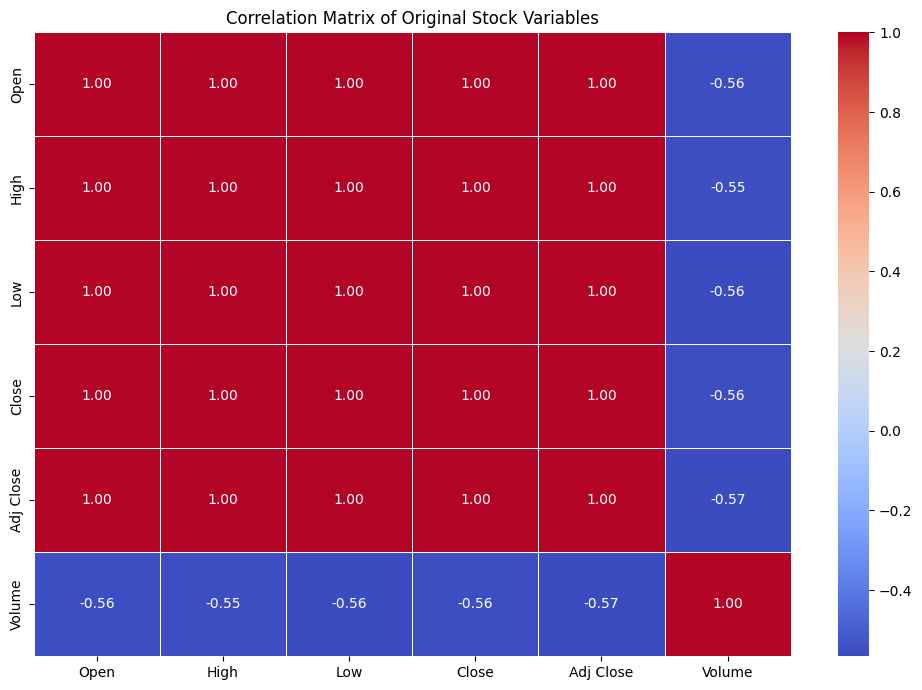

In [46]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Original Stock Variables")
plt.tight_layout()
plt.show()

###### A heatmap visualizes pairwise correlations. The analysis is limited to the original numeric variables to keep this first correlation view easy to interpret.
Colours make stronger relationships easier to see. Correlation does not prove that one variable causes another.

### Summarize yearly observations and prices

In [47]:
yearly_summary = data.groupby(data["Date"].dt.year).agg(
    Observations=("Date", "count"),
    Average_Close=("Close", "mean"),
    Average_Volume=("Volume", "mean"),
    Minimum_Close=("Close", "min"),
    Maximum_Close=("Close", "max")
)
yearly_summary.round(2)

,Observations,Average_Close,Average_Volume,Minimum_Close,Maximum_Close
Date,,,,,
2012,250,82.29,1.319642e+08,58.75,100.30
2013,252,67.52,1.016087e+08,55.79,81.44
2014,252,92.26,6.315273e+07,71.40,119.00
2015,252,120.04,5.184940e+07,103.12,133.00
2016,252,104.60,3.842253e+07,90.34,118.25
2017,251,150.55,2.713457e+07,116.02,176.42
2018,251,189.05,3.402006e+07,146.83,232.07
2019,251,207.92,2.804224e+07,142.19,291.52


##### Year-level summaries report observation counts, average volume and closing-price statistics. They support historical description while retaining the daily series for modeling.
This gives a year-by-year overview of the dataset.

### Calculate annual returns

In [48]:
year_end_close = data.set_index("Date")["Close"].resample("YE").last().dropna()
annual_returns = year_end_close.pct_change() * 100
annual_summary = pd.DataFrame({
    "Year_End_Close": year_end_close,
    "Annual_Return_Percent": annual_returns
})
annual_summary.round(2)

,Year_End_Close,Annual_Return_Percent
Date,,
2012-12-31,76.02,NaN
2013-12-31,80.15,5.42
2014-12-31,110.38,37.72
2015-12-31,105.26,-4.64
2016-12-31,115.82,10.03
2017-12-31,169.23,46.11
2018-12-31,157.74,-6.79
2019-12-31,291.52,84.81


##### The final available close in each calendar year is used to calculate year-over-year percentage returns. The first annual return is missing because the previous year-end price is not present in the dataset.
This compares each year's final closing price with the previous year's final close. The first year has no annual return within the available history.

# Feature engineering — creating model-oriented features

### Create a separate feature-engineering DataFrame

In [49]:
feature_data = data.copy()
feature_data = feature_data.sort_values("Date").reset_index(drop=True)

##### A separate copy is created for feature engineering so the earlier EDA results and the original source data remain available. Chronological order is reasserted before creating lagged and rolling features.
We work on a separate copy so it is easier to distinguish exploratory work from the dataset prepared for modeling.

### Create return and intraday-range features

In [50]:
feature_data["Daily_Return"] = feature_data["Close"].pct_change()
feature_data["Intraday_Range"] = feature_data["High"] - feature_data["Low"]
feature_data["Intraday_Range_Pct"] = (
    (feature_data["High"] - feature_data["Low"]) / feature_data["Open"]
)
feature_data[["Date", "Close", "Daily_Return", "Intraday_Range", "Intraday_Range_Pct"]].head(10)

,Date,Close,Daily_Return,Intraday_Range,Intraday_Range_Pct
0,2012-01-03,58.747143,NaN,0.500000,0.008549
1,2012-01-04,59.062859,0.005374,0.771431,0.013171
2,2012-01-05,59.718571,0.011102,0.840000,0.014170
3,2012-01-06,60.342857,0.010454,0.504284,0.008409
4,2012-01-09,60.247143,-0.001586,0.914287,0.015041
5,2012-01-10,60.462856,0.003580,0.642856,0.010566
6,2012-01-11,60.364285,-0.001630,0.505715,0.008375
7,2012-01-12,60.198570,-0.002745,0.592858,0.009828
8,2012-01-13,59.972858,-0.003749,0.255714,0.004265
9,2012-01-17,60.671429,0.011648,0.432858,0.007143


##### Daily return is the fractional change in Close from the prior observation. Intraday range is High minus Low; its normalized version divides that range by Open. These features use values from the same session or earlier observations, but for a forecast made before a session starts, same-session OHLC values would not be available. Feature availability must match the intended prediction time.
These features describe daily change and the size of the day's trading range. Important: if we forecast before a future trading day begins, we cannot use that future day's High, Low, Open or Close as input.

### Create lag features for closing prices

In [51]:
for lag in [1, 2, 3, 5, 10, 20]:
    feature_data[f"Close_Lag_{lag}"] = feature_data["Close"].shift(lag)

feature_data[["Date", "Close", "Close_Lag_1", "Close_Lag_5", "Close_Lag_20"]].head(25)

,Date,Close,Close_Lag_1,Close_Lag_5,Close_Lag_20
0,2012-01-03,58.747143,NaN,NaN,NaN
1,2012-01-04,59.062859,58.747143,NaN,NaN
2,2012-01-05,59.718571,59.062859,NaN,NaN
3,2012-01-06,60.342857,59.718571,NaN,NaN
4,2012-01-09,60.247143,60.342857,NaN,NaN
5,2012-01-10,60.462856,60.247143,58.747143,NaN
6,2012-01-11,60.364285,60.462856,59.062859,NaN
7,2012-01-12,60.198570,60.364285,59.718571,NaN
8,2012-01-13,59.972858,60.198570,60.342857,NaN
9,2012-01-17,60.671429,59.972858,60.247143,NaN


###### Lag features align prior closing-price observations with the current row. For example, Close_Lag_1 contains the previous recorded close. The initial rows are missing because earlier observations do not exist.
Lag 1 means yesterday's recorded close; lag 5 means the close five trading observations ago. These help the model use historical information.

### Create lag features for daily returns

In [52]:
for lag in [1, 2, 5, 10]:
    feature_data[f"Return_Lag_{lag}"] = feature_data["Daily_Return"].shift(lag)

feature_data[["Date", "Daily_Return", "Return_Lag_1", "Return_Lag_5"]].head(15)

,Date,Daily_Return,Return_Lag_1,Return_Lag_5
0,2012-01-03,NaN,NaN,NaN
1,2012-01-04,0.005374,NaN,NaN
2,2012-01-05,0.011102,0.005374,NaN
3,2012-01-06,0.010454,0.011102,NaN
4,2012-01-09,-0.001586,0.010454,NaN
5,2012-01-10,0.003580,-0.001586,NaN
6,2012-01-11,-0.001630,0.003580,0.005374
7,2012-01-12,-0.002745,-0.001630,0.011102
8,2012-01-13,-0.003749,-0.002745,0.010454
9,2012-01-17,0.011648,-0.003749,-0.001586


##### Lagged return features align historical returns with the current timestamp. They can provide information about recent momentum or reversal patterns, but their usefulness must be assessed on chronological validation data.
These features show recent past returns so a model can test whether earlier changes help forecast future values.

### Create rolling means and standard deviations using past observations

In [53]:
for window in [5, 10, 20, 50]:
    feature_data[f"Close_RollMean_{window}"] = (
        feature_data["Close"].rolling(window=window).mean()
    )
    feature_data[f"Return_RollStd_{window}"] = (
        feature_data["Daily_Return"].rolling(window=window).std()
    )

feature_data[[
    "Date", "Close_RollMean_5", "Close_RollMean_20",
    "Return_RollStd_5", "Return_RollStd_20"
]].tail()

,Date,Close_RollMean_5,Close_RollMean_20,Return_RollStd_5,Return_RollStd_20
2006,2019-12-23,280.721997,271.181998,0.007701,0.011232
2007,2019-12-24,281.493994,272.076997,0.007747,0.010795
2008,2019-12-26,283.527997,273.357997,0.010079,0.011062
2009,2019-12-27,285.483997,274.455997,0.010308,0.010918
2010,2019-12-30,287.899994,275.669496,0.009112,0.010826


##### Rolling means and standard deviations summarize recent price levels and return dispersion. The default rolling window includes the current row. For a forecast issued before the current session's close, shift these rolling features by one row so only information available before the forecast origin is used.
These features summarize recent trends and variability. If prediction happens before today's close, we must make sure today's price is not included in the inputs.

### Create calendar features

In [54]:
feature_data["Year"] = feature_data["Date"].dt.year
feature_data["Month"] = feature_data["Date"].dt.month
feature_data["DayOfWeek"] = feature_data["Date"].dt.dayofweek
feature_data["Quarter"] = feature_data["Date"].dt.quarter

feature_data[["Date", "Year", "Month", "DayOfWeek", "Quarter"]].head()

,Date,Year,Month,DayOfWeek,Quarter
0,2012-01-03,2012,1,1,1
1,2012-01-04,2012,1,2,1
2,2012-01-05,2012,1,3,1
3,2012-01-06,2012,1,4,1
4,2012-01-09,2012,1,0,1


##### Calendar features encode the year, month, weekday (Monday=0 through Sunday=6), and quarter of each recorded date. Their usefulness must be tested; calendar variables do not automatically imply seasonality.These let the model test whether calendar timing adds information. They do not prove that a seasonal pattern exists.

### Choose the forecasting target and create 30 future-session targets

In [55]:
TARGET_COLUMN = "Close"
FORECAST_HORIZON = 30

for horizon in range(1, FORECAST_HORIZON + 1):
    feature_data[f"Target_Close_t_plus_{horizon}"] = (
        feature_data[TARGET_COLUMN].shift(-horizon)
    )

target_columns = [
    f"Target_Close_t_plus_{h}" for h in range(1, FORECAST_HORIZON + 1)
]

feature_data[["Date", "Close"] + target_columns[:3] + target_columns[-1:]].tail(35)

,Date,Close,Target_Close_t_plus_1,Target_Close_t_plus_2,Target_Close_t_plus_3,Target_Close_t_plus_30
1976,2019-11-08,260.140015,262.200012,261.959991,264.470001,284.000000
1977,2019-11-11,262.200012,261.959991,264.470001,262.640015,284.269989
1978,2019-11-12,261.959991,264.470001,262.640015,265.760010,289.910004
1979,2019-11-13,264.470001,262.640015,265.760010,267.100006,289.799988
1980,2019-11-14,262.640015,265.760010,267.100006,266.290009,291.519989
1981,2019-11-15,265.760010,267.100006,266.290009,263.190002,NaN
1982,2019-11-18,267.100006,266.290009,263.190002,262.010010,NaN
1983,2019-11-19,266.290009,263.190002,262.010010,261.779999,NaN
1984,2019-11-20,263.190002,262.010010,261.779999,266.369995,NaN
1985,2019-11-21,262.010010,261.779999,266.369995,264.290009,NaN


##### For each row at time t, target column t+1 stores the next recorded session's close, while t+30 stores the close 30 recorded sessions ahead. This creates a direct multi-output target table. The target columns are labels only and must never be included among model input features. The final 30 rows lack complete future targets by construction.


### Inspect missing values introduced by feature engineering

In [56]:
engineered_missing = feature_data.isna().sum().sort_values(ascending=False)
print(engineered_missing.head(20))

MA_200                    199
Return_RollStd_50          50
MA_50                      49
Close_RollMean_50          49
Target_Close_t_plus_30     30
Target_Close_t_plus_29     29
Target_Close_t_plus_28     28
Target_Close_t_plus_27     27
Target_Close_t_plus_26     26
Target_Close_t_plus_25     25
Target_Close_t_plus_24     24
Target_Close_t_plus_23     23
Target_Close_t_plus_22     22
Target_Close_t_plus_21     21
Return_RollStd_20          20
Close_Lag_20               20
Volatility_20              20
Target_Close_t_plus_20     20
Close_RollMean_20          19
MA_20                      19
dtype: int64


##### Lag, rolling and future-target operations create expected missing values at the beginning or end of the dataset. These must be handled deliberately when preparing training rows; they should not be filled with arbitrary values.
Lag features need earlier rows, rolling features need enough history, and targets need future rows. So missing values at the edges are expected.

### Define the candidate input features

In [57]:
base_feature_columns = [
    "Open", "High", "Low", "Close", "Volume",
    "Daily_Return", "Intraday_Range", "Intraday_Range_Pct",
    "Year", "Month", "DayOfWeek", "Quarter"
]
lag_feature_columns = [
    f"Close_Lag_{lag}" for lag in [1, 2, 3, 5, 10, 20]
] + [
    f"Return_Lag_{lag}" for lag in [1, 2, 5, 10]
]
rolling_feature_columns = [
    f"Close_RollMean_{window}" for window in [5, 10, 20, 50]
] + [
    f"Return_RollStd_{window}" for window in [5, 10, 20, 50]
]

candidate_feature_columns = (
    base_feature_columns + lag_feature_columns + rolling_feature_columns
)

print("Candidate feature count:", len(candidate_feature_columns))
print(candidate_feature_columns)

Candidate feature count: 30
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Intraday_Range', 'Intraday_Range_Pct', 'Year', 'Month', 'DayOfWeek', 'Quarter', 'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_3', 'Close_Lag_5', 'Close_Lag_10', 'Close_Lag_20', 'Return_Lag_1', 'Return_Lag_2', 'Return_Lag_5', 'Return_Lag_10', 'Close_RollMean_5', 'Close_RollMean_10', 'Close_RollMean_20', 'Close_RollMean_50', 'Return_RollStd_5', 'Return_RollStd_10', 'Return_RollStd_20', 'Return_RollStd_50']


##### Candidate predictors are explicitly listed to prevent target columns from accidentally entering the input matrix. Before modeling, the team must define the forecast origin: same-row OHLC/volume and rolling features that include the current close are valid only if those values are already observed at prediction time. For a forecast made after the latest close, future recursive forecasts need a different strategy because future OHLC and volume are unknown.
We list the possible inputs explicitly so future target columns cannot accidentally become model inputs. We must only use information that would genuinely be known when making the forecast.

### Create a direct multi-output modeling table

In [58]:
model_columns = candidate_feature_columns + target_columns
model_data = feature_data[["Date"] + model_columns].dropna().reset_index(drop=True)

print("Model table shape:", model_data.shape)
print("First target columns:", target_columns[:3])
print("Last target column:", target_columns[-1])
model_data[["Date"] + candidate_feature_columns[:5] + target_columns[:3]].head()

Model table shape: (1931, 61)
First target columns: ['Target_Close_t_plus_1', 'Target_Close_t_plus_2', 'Target_Close_t_plus_3']
Last target column: Target_Close_t_plus_30


,Date,Open,High,Low,Close,Volume,Target_Close_t_plus_1,Target_Close_t_plus_2,Target_Close_t_plus_3
0,2012-03-15,85.658569,85.715714,82.650002,83.651428,289929500,83.652855,85.871429,86.565712
1,2012-03-16,83.531425,84.171425,82.571426,83.652855,206371900,85.871429,86.565712,86.071426
2,2012-03-19,85.481430,85.967140,84.150002,85.871429,225309000,86.565712,86.071426,85.620003
3,2012-03-20,85.644287,86.699997,84.497147,86.565712,204165500,86.071426,85.620003,85.150002
4,2012-03-21,86.105713,87.092857,85.915718,86.071426,161010500,85.620003,85.150002,86.711426


##### A candidate modeling table is created by selecting explicit predictors and the 30 target columns, then dropping rows with unavailable lag, rolling or future-target values. This is a direct multi-output setup; it is not yet a validated training/test split. Predictor availability must be aligned to the forecast origin before modeling.
This creates a table where each row has complete inputs and all 30 future answers. Early rows are removed because they lack enough history, and late rows are removed because future answers are not in the dataset.

### Check chronological split boundaries

##### An initial chronological 80/20 boundary is displayed for planning. In final model evaluation, multi-step target windows can overlap across the split; use a carefully designed time-series validation procedure and consider a gap/embargo so training labels do not extend into the test period. Do not treat this preview as the final evaluation design.
This shows what an in-time split looks like: earlier rows for training and later rows for testing. Before final evaluation, we must make sure the 30-step targets from training do not overlap into the test period

### Save EDA and engineered feature outputs

In [59]:
data.to_csv("apple_eda_output.csv", index=False)
feature_data.to_csv("apple_feature_engineering_all.csv", index=False)
model_data.to_csv("apple_model_table_direct_30_sessions.csv", index=False)

print("Saved:")
print("- apple_eda_output.csv")
print("- apple_feature_engineering_all.csv")
print("- apple_model_table_direct_30_sessions.csv")

Saved:
- apple_eda_output.csv
- apple_feature_engineering_all.csv
- apple_model_table_direct_30_sessions.csv


##### Three separate outputs are saved: the EDA working data, the full feature-engineered table including edge missingness, and a candidate direct 30-session modeling table. These are artifacts for inspection, not a claim that the feature set is final or leakage-free for every forecast origin.
This saves your work in separate files. Keep the raw CSV unchanged. We will review the model table and feature availability before training any model.

### Week 2 - MODEL BUILDING AND MODEL EVALUATION

- **Statistical time-series models:** ARIMA and SARIMA
- **Machine-learning models:** XGBoost and Random Forest
- **Hyperparameter tuning:** Grid search with chronological time-series cross-validation for the machine-learning models, plus a small validation grid for ARIMA/SARIMA orders.

**Forecast definition:** after the closing price on an observed date *t* is known, forecast the next **30 trading sessions** (not 30 calendar days). Since the dataset ends in 2019, this is a historical backtest, not a live forecast.

**Evaluation design:** hold out the final 30 observed closing prices as one untouched forecast window. Machine-learning training rows are purged so their 30-step labels cannot overlap the held-out window. Model selection uses earlier data only. All model comparisons use the same 30 actual closing prices.

## 1. Import modeling libraries and set reproducibility options

`XGBoost` is an additional dependency. If it is missing in your environment, uncomment and run the installation command below, then restart the kernel if required.

In [60]:
# If XGBoost is not installed, uncomment the next line and run it once:
# %pip install xgboost
# If TensorFlow is not installed, uncomment the next line and run it once:
# %pip install tensorflow

import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from xgboost import XGBRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import joblib

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
FORECAST_HORIZON = 30
N_SPLITS = 3
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

print("Modeling libraries imported successfully, including TensorFlow/Keras for GRU.")

Modeling libraries imported successfully, including TensorFlow/Keras for GRU.


## 2. Prepare training data and the final 30-session test window

Each row in `feature_data` has input features and 30 target columns. We use the last complete row as the forecast origin. Its target columns are the actual closing prices for the final 30 sessions.

To avoid overlap between training targets and the final test period, we remove training rows whose 30-session target windows would reach into that test period.

In [61]:
# Confirm that the earlier feature-engineering cells were run
assert "feature_data" in globals(), "Run the feature-engineering cells first."
assert "candidate_feature_columns" in globals(), "Input feature list not found."

target_columns = [
    f"Target_Close_t_plus_{step}"
    for step in range(1, FORECAST_HORIZON + 1)
]

missing = [col for col in target_columns if col not in feature_data.columns]
if missing:
    raise ValueError(f"Missing target columns: {missing[:3]}")

# Keep the date, input features, and future target columns
model_data = feature_data[
    ["Date"] + candidate_feature_columns + target_columns
].copy()

model_data["Date"] = pd.to_datetime(model_data["Date"])
model_data = (
    model_data.dropna(subset=candidate_feature_columns + target_columns)
    .sort_values("Date")
    .reset_index(drop=True)
)

# Last row with all 30 future target values
forecast_row = model_data.iloc[-1]
forecast_date = forecast_row["Date"]
actual_prices = forecast_row[target_columns].to_numpy(dtype=float)

# Dates for those 30 actual prices
ordered_data = data[["Date", "Close"]].copy()
ordered_data["Date"] = pd.to_datetime(ordered_data["Date"])
ordered_data = ordered_data.sort_values("Date").reset_index(drop=True)

origin_index = ordered_data.index[ordered_data["Date"] == forecast_date]
if len(origin_index) != 1:
    raise ValueError("Could not find the forecast date in the original data.")
origin_index = int(origin_index[0])

test_dates = ordered_data["Date"].iloc[
    origin_index + 1 : origin_index + 1 + FORECAST_HORIZON
].reset_index(drop=True)

if len(test_dates) != FORECAST_HORIZON:
    raise ValueError("There are not 30 actual sessions after the forecast date.")

# Training rows must finish their target windows before the test window
last_training_origin = origin_index - FORECAST_HORIZON
training_dates = set(ordered_data["Date"].iloc[:last_training_origin + 1])

train_data = model_data[model_data["Date"].isin(training_dates)].copy()

X_train = train_data[candidate_feature_columns].astype(float)
y_train = train_data[target_columns].astype(float)

# One row of known features used to predict the next 30 sessions
X_forecast = forecast_row[candidate_feature_columns].astype(float).to_frame().T

# Historical close series for ARIMA and SARIMA
close_series = (
    ordered_data.set_index("Date")["Close"].astype(float)
)

print("Forecast origin:", forecast_date.date())
print("Test dates:", test_dates.iloc[0].date(), "to", test_dates.iloc[-1].date())
print("Training rows:", len(X_train))
print("Number of input features:", X_train.shape[1])

Forecast origin: 2019-11-14
Test dates: 2019-11-15 to 2019-12-30
Training rows: 1901
Number of input features: 30


## 3. Create a function to measure model performance

We will use three standard metrics:

- **MAE:** average absolute prediction error; lower is better.
- **RMSE:** penalizes large errors more strongly; lower is better.
- **MAPE:** average percentage error; lower is better.

All models will be compared against the same 30 actual closing prices.

In [62]:
def evaluate_model(actual, predicted):
    actual = np.asarray(actual, dtype=float).ravel()
    predicted = np.asarray(predicted, dtype=float).ravel()

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}


results = []
predictions = pd.DataFrame({
    "Date": test_dates,
    "Actual_Close": actual_prices
})

## 4. Build the ARIMA model

ARIMA uses past closing prices to forecast future prices. Its parameters are `(p, d, q)`. We test a few combinations on an earlier validation period, choose the one with the lowest validation MAE, and then fit that configuration using all data available up to the forecast date.

In [63]:
# Use the 30 sessions before the final test period for validation
validation_end = origin_index
validation_start = validation_end - FORECAST_HORIZON + 1

# Reset the index to a RangeIndex to prevent statsmodels from raising frequency-related index errors
validation_train = close_series.iloc[:validation_start].reset_index(drop=True)
validation_actual = close_series.iloc[
    validation_start : validation_end + 1
].to_numpy(dtype=float)

# A small, easy-to-understand ARIMA parameter search
arima_orders = [(1, 1, 0), (1, 1, 1), (2, 1, 1), (2, 1, 2), (3, 1, 1)]
arima_scores = []

for order in arima_orders:
    fitted = ARIMA(validation_train, order=order).fit()
    validation_prediction = fitted.forecast(steps=FORECAST_HORIZON)
    score = evaluate_model(validation_actual, validation_prediction)
    arima_scores.append({"order": order, **score})

arima_table = pd.DataFrame(arima_scores).sort_values("MAE")
display(arima_table)

best_arima_order = arima_table.iloc[0]["order"]
print("Selected ARIMA order:", best_arima_order)

# Fit the selected model and forecast the final 30 sessions
arima_model = ARIMA(
    close_series.iloc[:origin_index + 1].reset_index(drop=True),
    order=best_arima_order
).fit()

arima_prediction = np.asarray(
    arima_model.forecast(steps=FORECAST_HORIZON)
)

results.append({
    "Model": "ARIMA",
    "Best parameters": str(best_arima_order),
    **evaluate_model(actual_prices, arima_prediction)
})
predictions["ARIMA"] = arima_prediction

,order,MAE,RMSE,MAPE (%)
3,"(2, 1, 2)",23.798883,26.781518,9.492080
4,"(3, 1, 1)",23.803158,26.784845,9.493853
2,"(2, 1, 1)",23.832071,26.810382,9.505697
1,"(1, 1, 1)",24.030398,26.984478,9.587008
0,"(1, 1, 0)",24.030496,26.984768,9.587039


Selected ARIMA order: (2, 1, 2)


## 5. Build the SARIMA model

SARIMA is similar to ARIMA but also includes seasonal terms. Here, `s` is used as a candidate seasonal period to represent approximately five trading sessions. This is an assumption to test, not a guarantee that prices have weekly seasonality.

In [64]:
# Test a small set of SARIMA configurations
sarima_options = [
    ((1, 1, 1), (1, 0, 1, 5)),
    ((1, 1, 1), (1, 1, 1, 5)),
    ((2, 1, 1), (1, 0, 1, 5)),
    ((1, 1, 2), (0, 1, 1, 5)),
]
sarima_scores = []

for order, seasonal_order in sarima_options:
    fitted = SARIMAX(
        validation_train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    validation_prediction = fitted.forecast(steps=FORECAST_HORIZON)
    score = evaluate_model(validation_actual, validation_prediction)

    sarima_scores.append({
        "order": order,
        "seasonal_order": seasonal_order,
        **score
    })

sarima_table = pd.DataFrame(sarima_scores).sort_values("MAE")
display(sarima_table)

best_sarima_order = sarima_table.iloc[0]["order"]
best_seasonal_order = sarima_table.iloc[0]["seasonal_order"]

print("Selected SARIMA order:", best_sarima_order)
print("Selected seasonal order:", best_seasonal_order)

# Fit selected SARIMA model and forecast the final 30 sessions
# Reset the index to a RangeIndex to prevent statsmodels from raising frequency-related index errors
sarima_model = SARIMAX(
    close_series.iloc[:origin_index + 1].reset_index(drop=True),
    order=best_sarima_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_prediction = np.asarray(
    sarima_model.forecast(steps=FORECAST_HORIZON)
)

results.append({
    "Model": "SARIMA",
    "Best parameters": f"{best_sarima_order}, {best_seasonal_order}",
    **evaluate_model(actual_prices, sarima_prediction)
})
predictions["SARIMA"] = sarima_prediction

,order,seasonal_order,MAE,RMSE,MAPE (%)
3,"(1, 1, 2)","(0, 1, 1, 5)",22.549343,25.349593,8.994893
1,"(1, 1, 1)","(1, 1, 1, 5)",22.684178,25.467465,9.050197
2,"(2, 1, 1)","(1, 0, 1, 5)",23.810719,26.792282,9.496914
0,"(1, 1, 1)","(1, 0, 1, 5)",24.015488,26.972237,9.580855


Selected SARIMA order: (1, 1, 2)
Selected seasonal order: (0, 1, 1, 5)


## 6. Machine-learning models — chronological cross-validation and grid search

Random Forest combines many decision trees. Since the target has 30 columns, `MultiOutputRegressor` trains one Random Forest for each future session.

`GridSearchCV` compares a small set of tree settings. `TimeSeriesSplit` keeps each validation fold later in time than its training fold.

In [65]:
# Time-series cross-validation; the gap helps avoid overlapping 30-session targets
time_cv = TimeSeriesSplit(n_splits=3, gap=FORECAST_HORIZON)

rf_model = MultiOutputRegressor(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)
)

rf_parameters = {
    "estimator__n_estimators": [100, 200],
    "estimator__max_depth": [None, 12],
    "estimator__min_samples_leaf": [1, 3],
}

rf_search = GridSearchCV(
    rf_model,
    param_grid=rf_parameters,
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("Best Random Forest settings:", rf_search.best_params_)

rf_prediction = rf_search.best_estimator_.predict(X_forecast).ravel()

results.append({
    "Model": "Random Forest",
    "Best parameters": str(rf_search.best_params_),
    **evaluate_model(actual_prices, rf_prediction)
})
predictions["Random Forest"] = rf_prediction

Best Random Forest settings: {'estimator__max_depth': None, 'estimator__min_samples_leaf': 3, 'estimator__n_estimators': 100}


## 7. Build and tune the XGBoost model

XGBoost builds decision trees sequentially, with each tree helping improve the ensemble. We tune the number of trees and tree depth using the same chronological cross-validation approach as Random Forest.

In [66]:
# XGBoost grid search
xgb_model = MultiOutputRegressor(
    XGBRegressor(
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=0
    )
)

xgb_parameters = {
    "estimator__n_estimators": [100, 200],
    "estimator__max_depth": [2, 4],
    "estimator__learning_rate": [0.05, 0.1],
}

xgb_search = GridSearchCV(
    xgb_model,
    param_grid=xgb_parameters,
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=1
)

xgb_search.fit(X_train, y_train)
print("Best XGBoost settings:", xgb_search.best_params_)
xgb_prediction = xgb_search.best_estimator_.predict(X_forecast).ravel()
results.append({
    "Model": "XGBoost",
    "Best parameters": str(xgb_search.best_params_),
    **evaluate_model(actual_prices, xgb_prediction)
})
predictions["XGBoost"] = xgb_prediction

Best XGBoost settings: {'estimator__learning_rate': 0.05, 'estimator__max_depth': 2, 'estimator__n_estimators': 200}


## 8. Build and train the GRU model

GRU (Gated Recurrent Unit) is a recurrent neural network designed for sequential data. It uses update and reset gates to learn which past information should be retained or forgotten.

For this project, the GRU receives a sequence of the previous 20 trading-session feature rows and predicts the next 30 closing prices in one step. Input features and target prices are scaled because neural networks generally train more reliably when values are on comparable scales.

The model uses a chronological validation split and early stopping. No random shuffling is used, so the validation segment remains later in time than the training segment.

In [67]:
# Prepare sequential inputs for the GRU model
LOOKBACK = 20  # Number of previous feature rows supplied to the GRU

# Use the chronological training rows prepared above
gru_X_raw = train_data[candidate_feature_columns].astype(float).to_numpy()
gru_y_raw = train_data[target_columns].astype(float).to_numpy()

def make_sequences(features, targets, lookback):
    X_seq, y_seq = [], []
    for end_idx in range(lookback - 1, len(features)):
        start_idx = end_idx - lookback + 1
        X_seq.append(features[start_idx:end_idx + 1])
        y_seq.append(targets[end_idx])
    return np.asarray(X_seq), np.asarray(y_seq)

X_gru, y_gru = make_sequences(gru_X_raw, gru_y_raw, LOOKBACK)

if len(X_gru) < 10:
    raise ValueError("Not enough training sequences for GRU. Reduce LOOKBACK or check the training data.")

# Scale input features. Fit the scaler only on training data.
x_scaler = StandardScaler()
x_scaler.fit(gru_X_raw)

X_gru_scaled = x_scaler.transform(
    X_gru.reshape(-1, X_gru.shape[-1])
).reshape(X_gru.shape)

# Scale the 30 output prices, fitting only on training targets.
y_scaler = StandardScaler()
y_scaler.fit(y_gru)
y_gru_scaled = y_scaler.transform(y_gru)

# Build the GRU network: sequence input -> GRU layer -> 30 price outputs
gru_model = Sequential([
    Input(shape=(LOOKBACK, X_gru_scaled.shape[2])),
    GRU(32, activation="tanh"),
    Dropout(0.2),
    Dense(30)
])

gru_model.compile(optimizer="adam", loss="mean_squared_error")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = gru_model.fit(
    X_gru_scaled,y_gru_scaled,epochs=100,batch_size=32,
    validation_split=0.2,shuffle=False,callbacks=[early_stop],verbose=1
)

# Create the latest 20-session feature sequence ending at the forecast origin
history_features = model_data.loc[
    model_data["Date"] <= forecast_date, candidate_feature_columns
].astype(float).to_numpy()

if len(history_features) < LOOKBACK:
    raise ValueError("Not enough historical feature rows to create the GRU forecast sequence.")

latest_sequence = history_features[-LOOKBACK:]
latest_sequence_scaled = x_scaler.transform(latest_sequence)
latest_sequence_scaled = latest_sequence_scaled.reshape(
    1, LOOKBACK, len(candidate_feature_columns)
)

gru_prediction_scaled = gru_model.predict(latest_sequence_scaled, verbose=0)
gru_prediction = y_scaler.inverse_transform(gru_prediction_scaled).ravel()

results.append({
    "Model": "GRU",
    "Best parameters": f"lookback={LOOKBACK}, GRU units=32, dropout=0.2, batch_size=32",
    **evaluate_model(actual_prices, gru_prediction)
})
predictions["GRU"] = gru_prediction

print("GRU training complete. 30-session forecast generated.")

Epoch 1/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.4763 - val_loss: 1.0162
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1590 - val_loss: 0.5027
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1000 - val_loss: 0.3959
Epoch 4/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0822 - val_loss: 0.3317
Epoch 5/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0714 - val_loss: 0.2855
Epoch 6/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0638 - val_loss: 0.2655
Epoch 7/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0568 - val_loss: 0.2368
Epoch 8/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0523 - val_loss: 0.2168
Epoch 9/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0498 - val_loss: 0.1971
Epoch 10/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0449 - val_loss: 0.1871
Epoch 11/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0458 - val_loss: 0.1724
Epoch 12/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

## 9. Compare all four models

Lower MAE, RMSE, and MAPE indicate smaller errors on this held-out window. Use the selected metric that best matches the project objective; MAE is used as the default ranking metric because it is directly interpretable in the stock-price units.

In [68]:
results_table = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_table)

best_model = results_table.iloc[0]["Model"]
print("Lowest MAE on this test window:", best_model)

,Model,Best parameters,MAE,RMSE,MAPE (%)
0,SARIMA,"(1, 1, 2), (0, 1, 1, 5)",8.598407,11.626246,3.069416
1,ARIMA,"(2, 1, 2)",9.936439,13.289916,3.548267
2,GRU,"lookback=20, GRU units=32, dropout=0.2, batch_...",39.930467,40.841768,14.594225
3,XGBoost,"{'estimator__learning_rate': 0.05, 'estimator_...",69.789097,72.011002,25.481674
4,Random Forest,"{'estimator__max_depth': None, 'estimator__min...",69.942447,72.828002,25.495670


Lowest MAE on this test window: SARIMA


### Note:

The winner is based on one historical 30-session window and is not evidence of guaranteed future superiority.

## 10. Plot actual and predicted closing prices

The plot lets us visually compare each model's 30-session forecast with the actual closing prices.

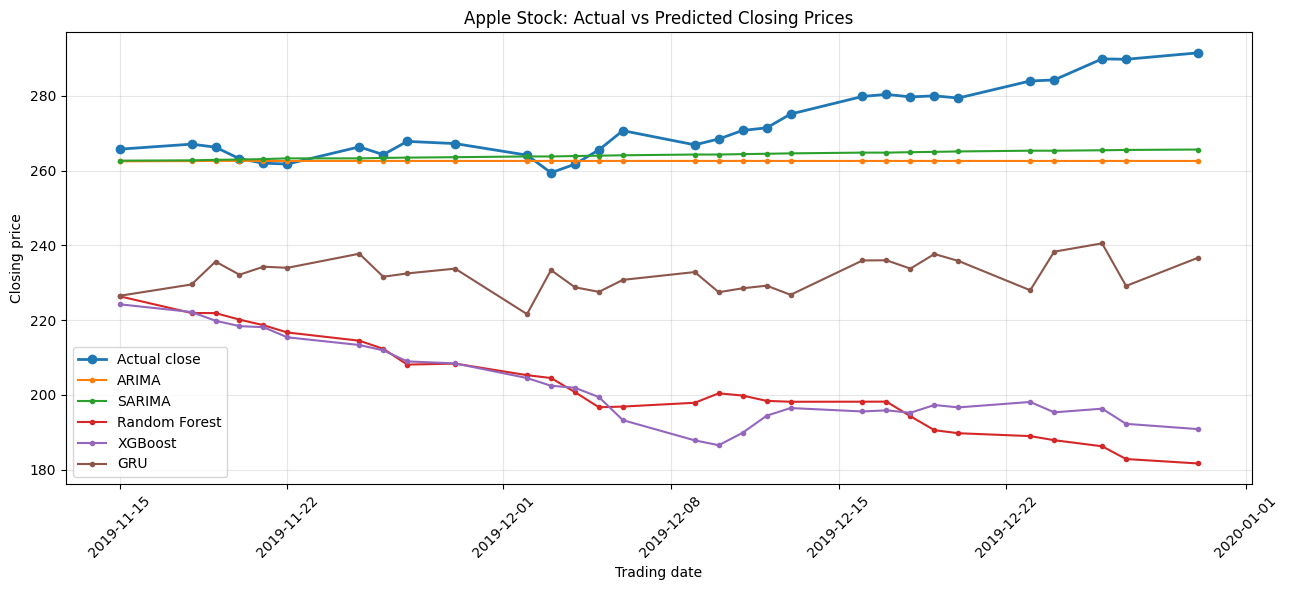

In [69]:
# Actual vs predicted closing prices for the held-out 30 trading sessions
plt.figure(figsize=(13, 6))
plt.plot(predictions["Date"], predictions["Actual_Close"],marker="o", label="Actual close", linewidth=2)

for name in ["ARIMA", "SARIMA", "Random Forest", "XGBoost", "GRU"]:
    plt.plot(predictions["Date"], predictions[name],marker=".", label=name)

plt.title("Apple Stock: Actual vs Predicted Closing Prices")
plt.xlabel("Trading date")
plt.ylabel("Closing price")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,Date,Actual_Close,ARIMA,SARIMA,Random Forest,XGBoost,GRU,ARIMA Error,SARIMA Error,Random Forest Error,XGBoost Error,GRU Error
0,2019-11-15,265.760010,262.503503,262.682757,226.394882,224.258698,226.532471,-3.256507,-3.077253,-39.365128,-41.501312,-39.227539
1,2019-11-18,267.100006,262.572697,262.769642,221.937948,222.192001,229.571350,-4.527309,-4.330364,-45.162058,-44.908005,-37.528656
2,2019-11-19,266.290009,262.627418,262.897483,221.898109,219.855087,235.678741,-3.662591,-3.392526,-44.391900,-46.434922,-30.611268
3,2019-11-20,263.190002,262.618924,262.985848,220.161124,218.416016,232.172180,-0.571078,-0.204154,-43.028878,-44.773986,-31.017822
4,2019-11-21,262.010010,262.601113,263.097680,218.663620,218.133804,234.316330,0.591103,1.087670,-43.346390,-43.876206,-27.693680
5,2019-11-22,261.779999,262.599778,263.296741,216.719654,215.424789,234.018982,0.819779,1.516742,-45.060345,-46.355210,-27.761017
6,2019-11-25,266.369995,262.604697,263.293891,214.520056,213.369705,237.786804,-3.765298,-3.076104,-51.849939,-53.000290,-28.583191
7,2019-11-26,264.290009,262.606141,263.411279,212.354201,211.935928,231.622223,-1.683868,-0.878730,-51.935808,-52.354081,-32.667786
8,2019-11-27,267.839996,262.605013,263.498426,208.125476,208.979675,232.521088,-5.234983,-4.341570,-59.714520,-58.860321,-35.318908
9,2019-11-29,267.250000,262.604349,263.610116,208.397735,208.446472,233.796036,-4.645651,-3.639884,-58.852265,-58.803528,-33.453964


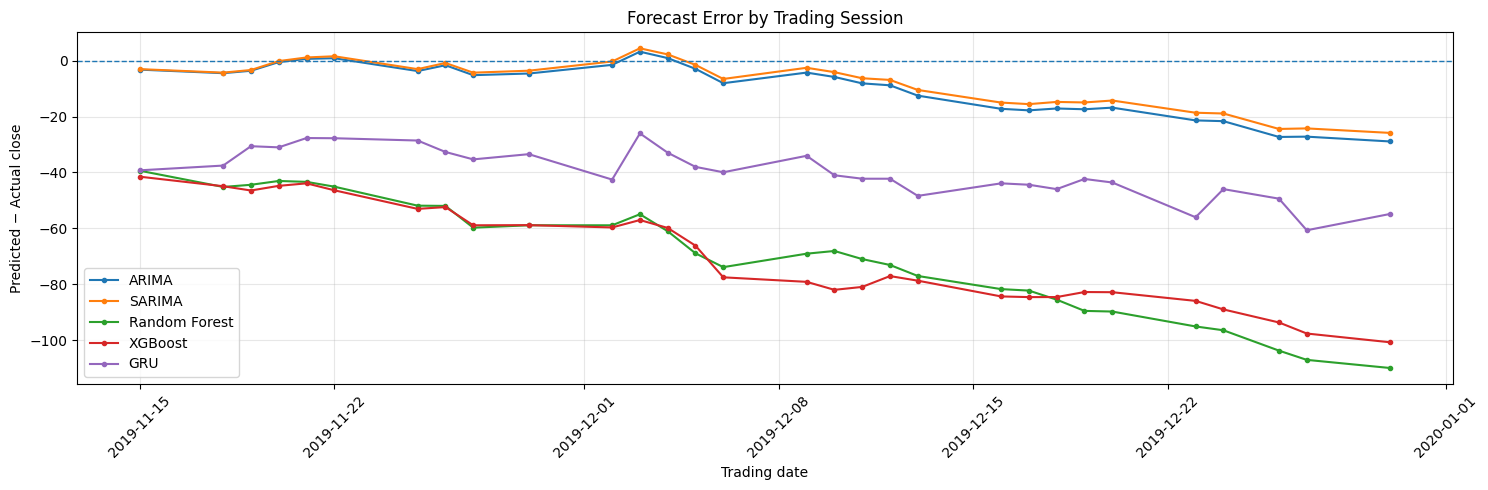

In [70]:
# Per-session forecast errors help show where each model over- or under-predicts.
error_columns = []
for model_name in ["ARIMA", "SARIMA", "Random Forest", "XGBoost", "GRU"]:
    if model_name in predictions.columns:
        err_col = f"{model_name} Error"
        predictions[err_col] = predictions[model_name] - predictions["Actual_Close"]
        error_columns.append(err_col)

display(predictions.head(10))
plt.figure(figsize=(15, 5))
for err_col in error_columns:
    plt.plot(predictions["Date"], predictions[err_col], marker=".", label=err_col.replace(" Error", ""))
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Forecast Error by Trading Session")
plt.xlabel("Trading date")
plt.ylabel("Predicted − Actual close")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Save evaluation outputs and tuned models

The CSV outputs contain the common test-window predictions and model metrics. The serialized Random Forest and XGBoost models, GRU network, GRU input/target scalers, and ARIMA/SARIMA fitted objects are saved. The GRU scalers and the same feature order must also be reused for inference. These models are trained on historical data ending in 2019 and should be retrained on current data before any real-world use.

In [71]:
predictions.to_csv("apple_30_session_test_predictions.csv", index=False)
results_table.to_csv("apple_model_evaluation_metrics.csv", index=False)

joblib.dump(rf_search.best_estimator_, "apple_random_forest_model.joblib")
joblib.dump(xgb_search.best_estimator_, "apple_xgboost_model.joblib")
joblib.dump(x_scaler, "apple_gru_input_scaler.joblib")
joblib.dump(y_scaler, "apple_gru_target_scaler.joblib")
gru_model.save("apple_gru_model.keras")
joblib.dump(arima_model, "apple_arima_model.joblib")
joblib.dump(sarima_model, "apple_sarima_model.joblib")
joblib.dump(candidate_feature_columns, "apple_feature_columns.joblib")

print("Saved predictions, evaluation metrics, and trained models.")

Saved predictions, evaluation metrics, and trained models.


## Summary and limitations

- Five models were compared: ARIMA, SARIMA, Random Forest, XGBoost, and GRU.
- MAE, RMSE, and MAPE were used to measure error.
- Random Forest and XGBoost used GridSearchCV with chronological cross-validation.
- GRU used 20-session input sequences, scaled features and targets, chronological validation, and early stopping.
- ARIMA and SARIMA used a small validation search over candidate parameter settings.
- The forecast covers 30 trading sessions, not 30 calendar days.
- The GRU network and its input/target scalers were saved for later loading; inference must apply the saved scalers and the same 20-session input sequence.
- The dataset ends in 2019, so this is a historical backtest rather than a current forecast.
- The CSV does not include external indicators such as earnings reports or S&P 500 values, so those factors are not modeled here.